## MVA - "Méthodes de séparation de sources pour l’analyse de données en astrophysique"

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from scripts.palm import PALM

# Retrieving the data

In [3]:
chandra_pickle = np.load("./data/chandra_data.npy", allow_pickle=True).item()

X_linear_model = chandra_pickle['LinModel']
A_linear_model = chandra_pickle['MixingMatrix']
S_all_models = chandra_pickle['Sources']
X_complex_model = chandra_pickle['ComplexSims']
X_real_data = chandra_pickle['RealData']

print("X_linear_model:", X_linear_model.shape)
print("A_linear_model:", A_linear_model.shape)
print("S_all_models:", S_all_models.shape)
print("X_complex_model:", X_complex_model.shape)
print("X_real_data:", X_real_data.shape)

X_linear_model: (40, 128, 128)
A_linear_model: (40, 3)
S_all_models: (3, 128, 128)
X_complex_model: (40, 230, 230)
X_real_data: (40, 256, 256)


In [4]:
A_est,S_est,it = PALM(X_linear_model.reshape(40,-1),A_linear_model,S_all_models.reshape(3,-1),lamb=0.01,itmax=100)

itmax 100


In [5]:
for A,X,S in [(A_linear_model,X_linear_model,S_all_models)]:
    print(X.shape)
    print(X.size)

(40, 128, 128)
655360


## real source 

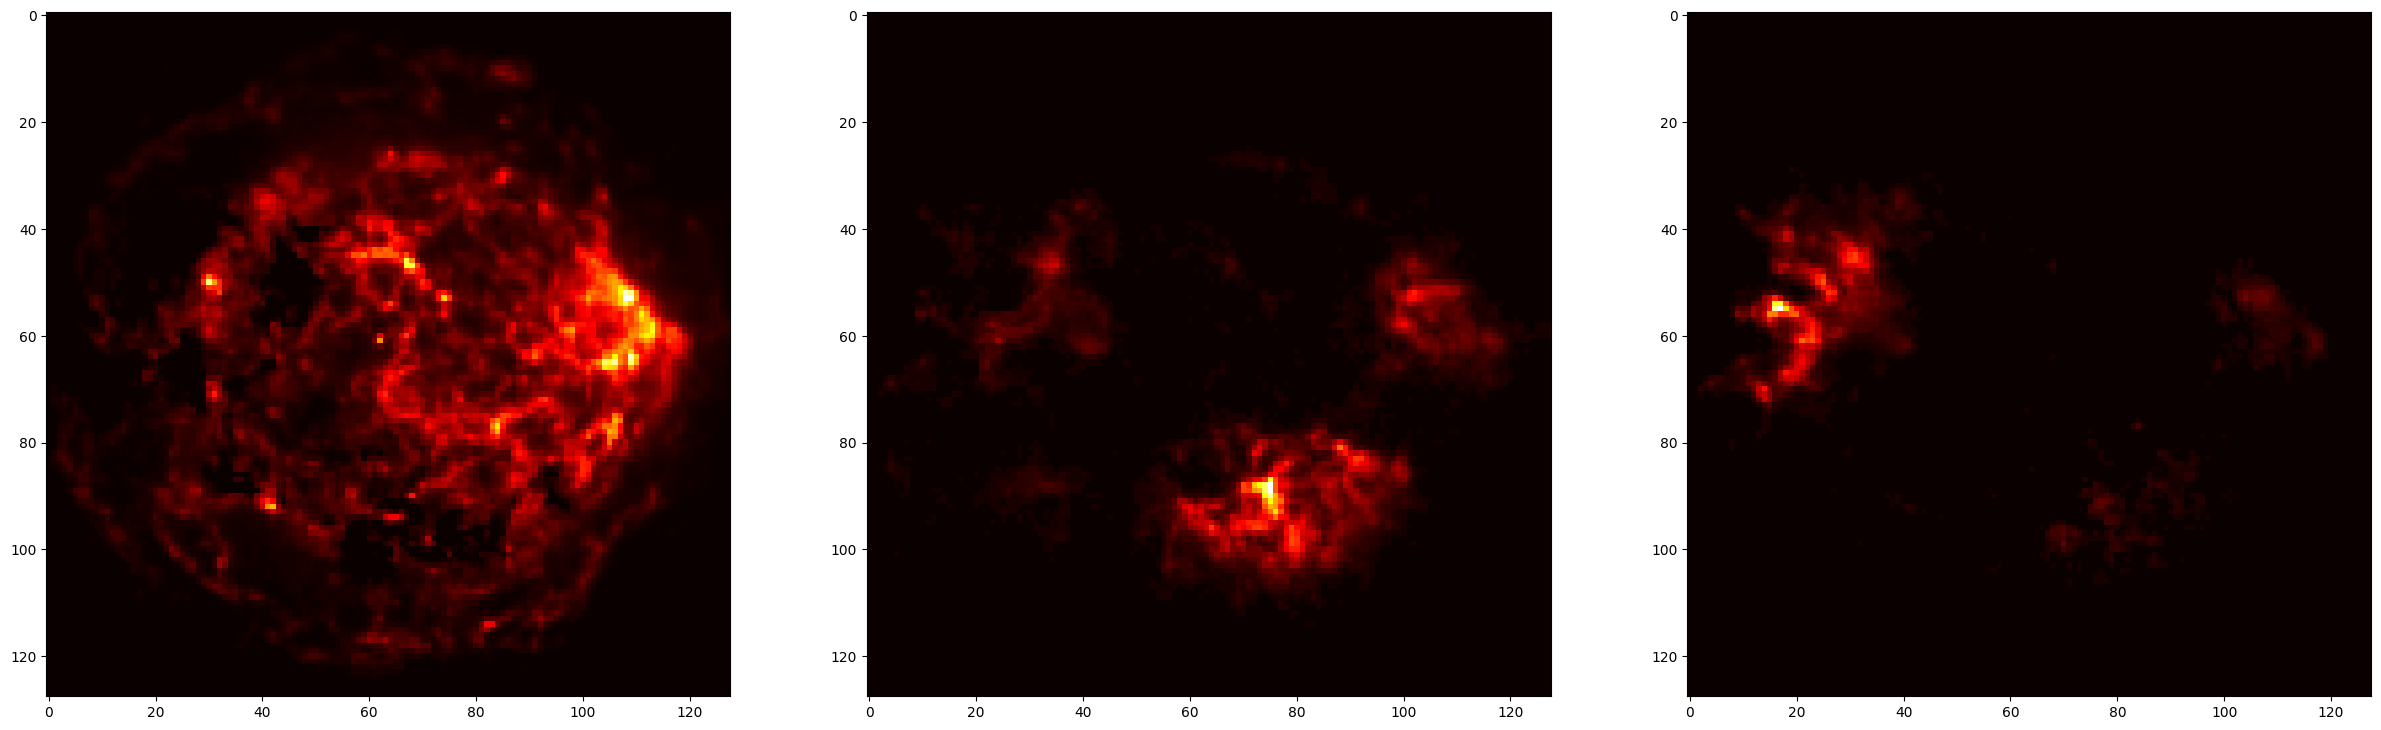

In [6]:
f,ax = plt.subplots(1,3,figsize=(30,15))
for k in range(3):
    ax[k].imshow(S[k],#.transpose(1,2,0),
              cmap='hot')
plt.show()

## Estimated source through Palm 

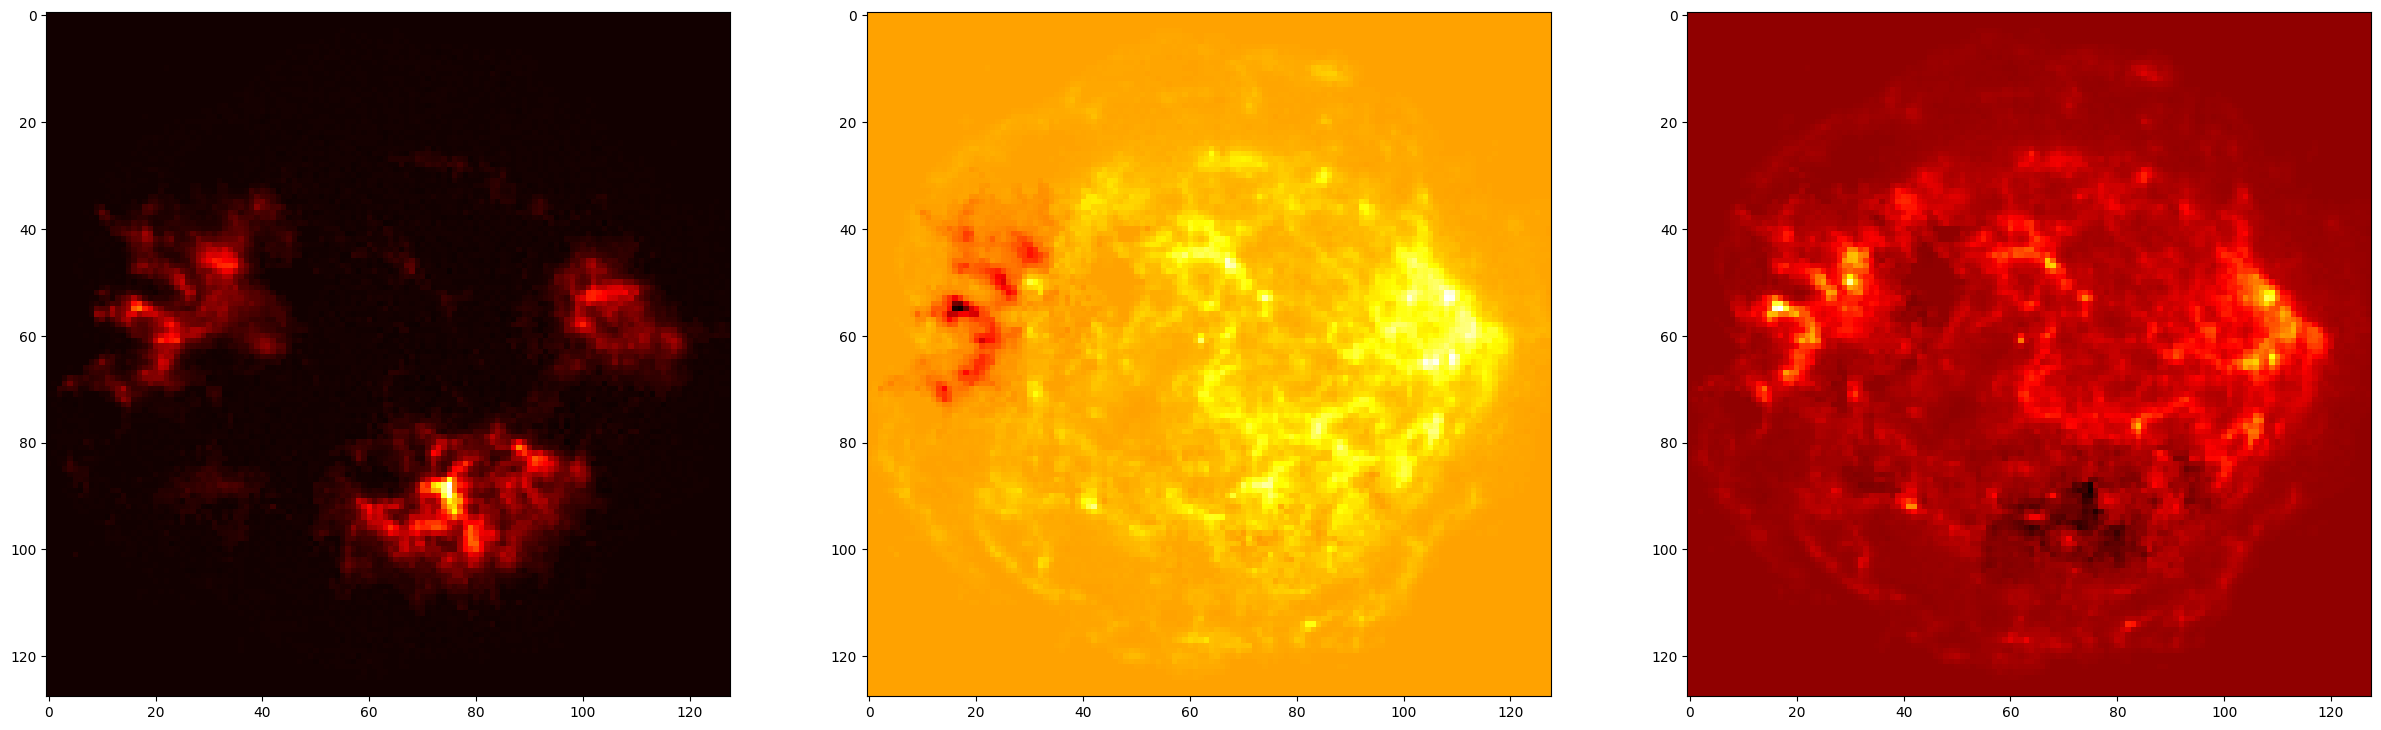

In [7]:
f,ax = plt.subplots(1,3,figsize=(30,15))
for k in range(3):
    ax[k].imshow(S_est[k].reshape(128,128),#.transpose(1,2,0),
              cmap='hot')
plt.show()

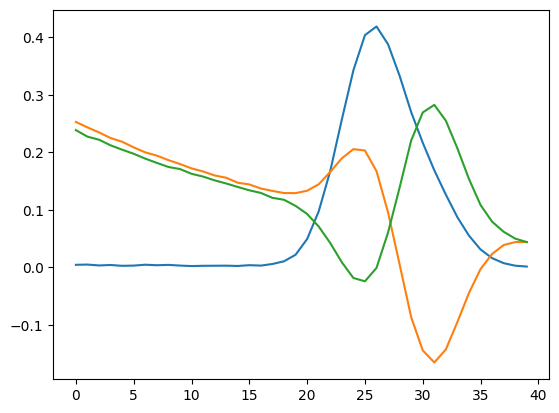

In [8]:
plt.plot(A_est)

In [9]:
from scripts.ista import ISTA_S

In [16]:
S_est,it = ISTA_S(X_linear_model.reshape(40,-1),A_linear_model,S_all_models.reshape(3,-1),lamb=1)

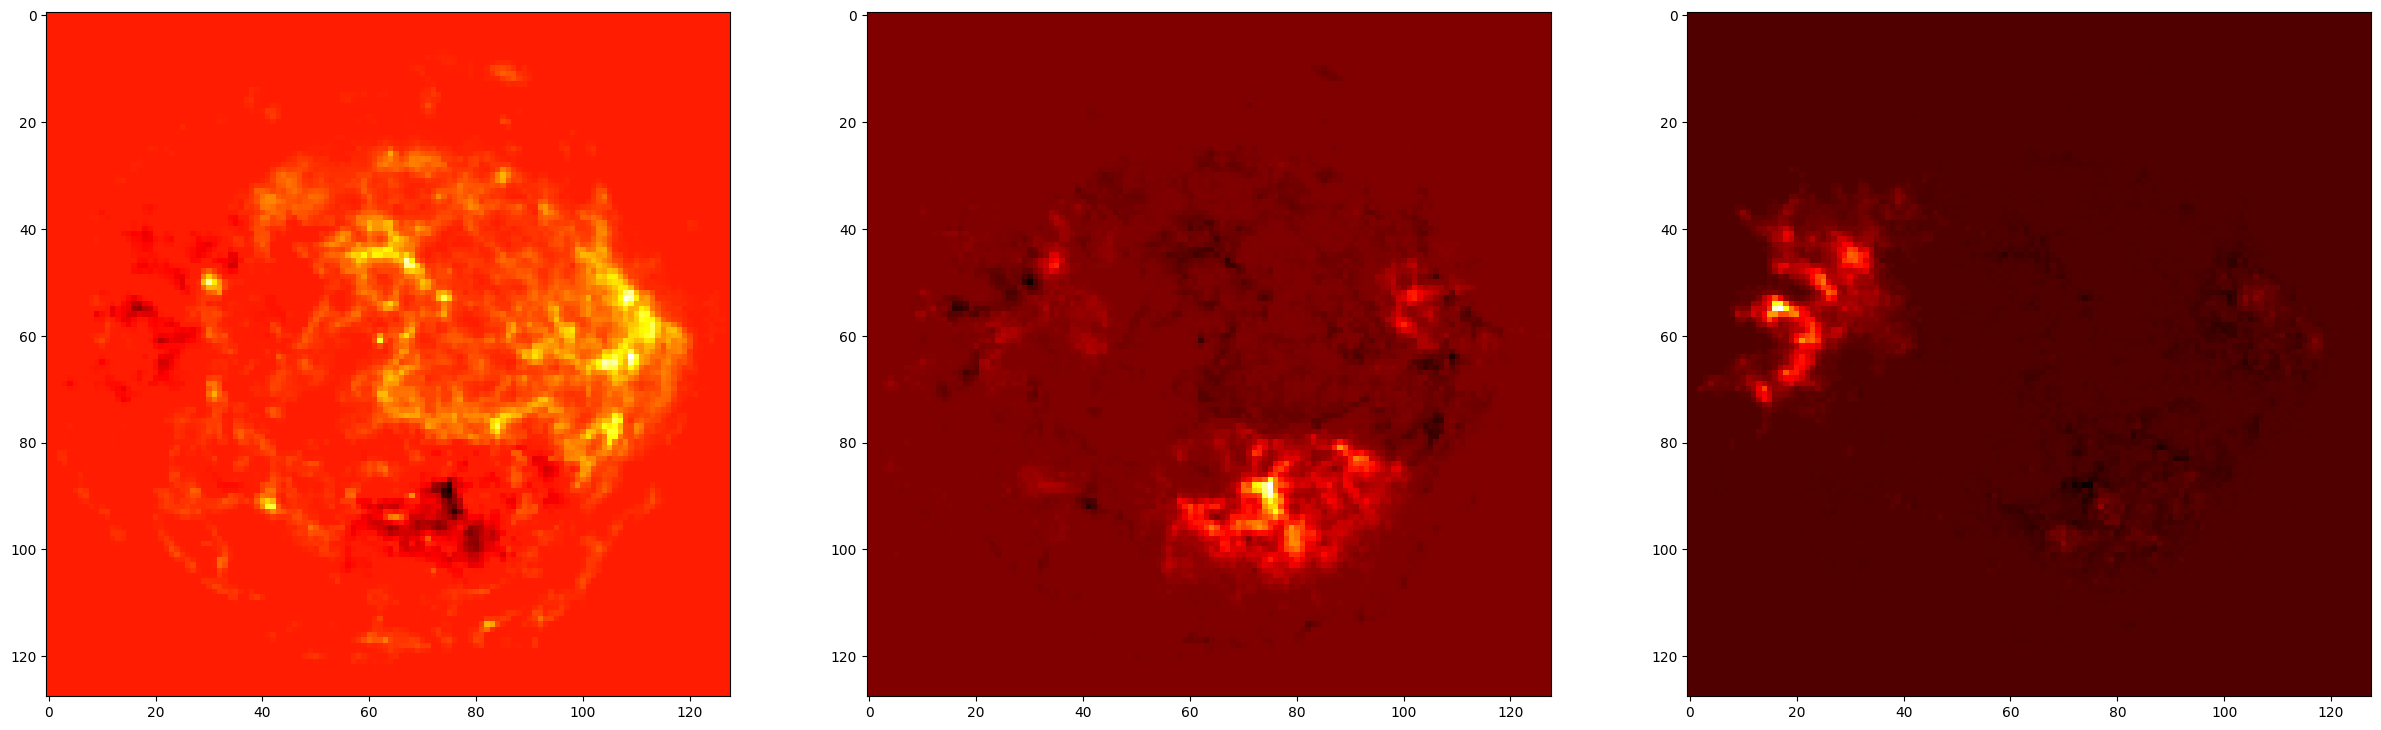

In [17]:
f,ax = plt.subplots(1,3,figsize=(30,15))
for k in range(3):
    ax[k].imshow(S_est.T[k].reshape(128,128),#.transpose(1,2,0),
              cmap='hot')
plt.show()

In [13]:
test = np.array([[1,2],[3,4]])

In [14]:
test.T

array([[1, 3],
       [2, 4]])

In [15]:
A_est,S_est,it

(array([[ 0.00448468,  0.2528358 ,  0.23866835],
        [ 0.0049213 ,  0.24333931,  0.22724666],
        [ 0.00338534,  0.23464881,  0.22195045],
        [ 0.00419418,  0.2248512 ,  0.21218612],
        [ 0.00272814,  0.21844248,  0.20461174],
        [ 0.00312369,  0.20862819,  0.19750659],
        [ 0.00466991,  0.19993508,  0.18906036],
        [ 0.00374633,  0.19429144,  0.18166628],
        [ 0.00435386,  0.18647182,  0.17458347],
        [ 0.00316526,  0.17968419,  0.17094418],
        [ 0.00229394,  0.17212936,  0.16271495],
        [ 0.00274997,  0.16675149,  0.15788902],
        [ 0.00289402,  0.15982732,  0.1512689 ],
        [ 0.00300036,  0.15582763,  0.14584236],
        [ 0.00249056,  0.14716969,  0.13980527],
        [ 0.00384417,  0.14420298,  0.13399565],
        [ 0.00312223,  0.13711036,  0.12943166],
        [ 0.0059243 ,  0.13294994,  0.1209287 ],
        [ 0.01060189,  0.12927017,  0.11754101],
        [ 0.02196149,  0.12908114,  0.10690606],
        [ 0.04931668